Analyse Part:

In [400]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("insurance.csv")
print(df)
df

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


Verify duplicate  informations

In [401]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1333    False
1334    False
1335    False
1336    False
1337    False
Length: 1338, dtype: bool

In [402]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [403]:
df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [404]:
df["smoker"]=df["smoker"].map({"yes":1,"no":0})
df["sex"]=df["sex"].map({"male":0,"female":1})
df["region"]=df["region"].map({"southwest":1,"northwest":0})
print(df["smoker"])
df.dtypes

0       1
1       0
2       0
3       0
4       0
       ..
1333    0
1334    0
1335    0
1336    0
1337    1
Name: smoker, Length: 1338, dtype: int64


age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
region      float64
charges     float64
dtype: object

Univariate analysis: Analyze each variable independently.

Variable : Smoker

smoker
0    1064
1     274
Name: count, dtype: int64


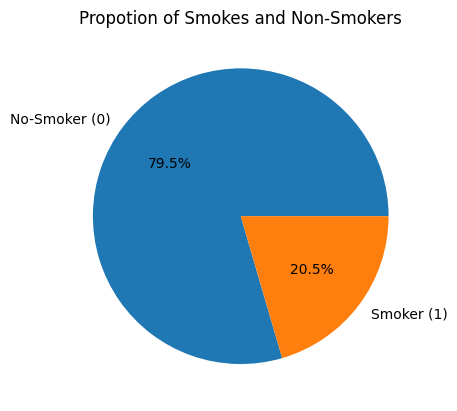

In [405]:

count_smocked=df["smoker"].value_counts()
print(count_smocked)
labels=["No-Smoker (0)", "Smoker (1)"]
plt.pie(count_smocked,labels=labels,autopct="%1.1f%%")
plt.title("Propotion of Smokes and Non-Smokers")
plt.show()

It is easy to observe that non-smokers outnumber smokers in the dataset.

Variable sex 

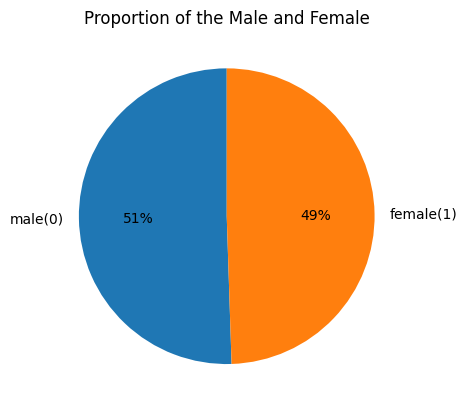

In [406]:
sex_count=df["sex"].value_counts()
label3=["male(0)","female(1)"]
plt.pie(sex_count,labels=label3,startangle=90,autopct="%.0f%%")
plt.title("Proportion of the Male and Female")
plt.show()


Variable Regions

region
1.0    325
0.0    325
Name: count, dtype: int64


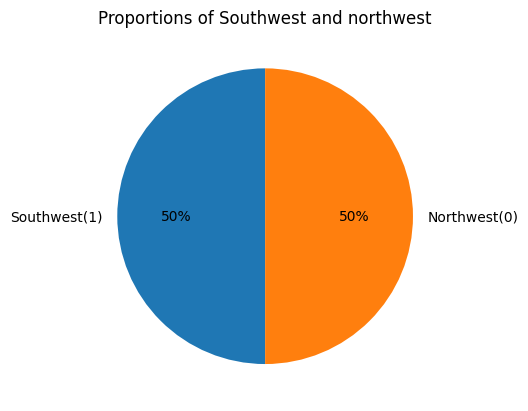

In [407]:
Regions_counts=df["region"].value_counts()
labels2=["Southwest(1)","Northwest(0)"]
print(Regions_counts)
plt.pie(Regions_counts,labels=labels2,autopct="%.0f%%",startangle=90)
plt.title("Proportions of Southwest and northwest")
plt.show()

Variable children

Text(0.5, 1.0, 'Proportions of children')

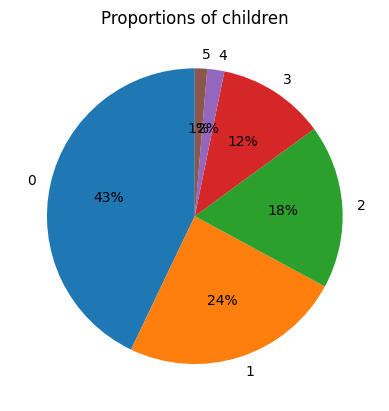

In [408]:
children_count=df["children"].value_counts()
labels = ["0","1","2","3","4","5"]
plt.pie(children_count,labels=labels,autopct="%0.0f%%",startangle=90)
plt.title("Proportions of children")

Correlation of variables: Examine correlations with the target variable.

In [409]:
df1=df.drop("region",axis=1)
correlations=df1.corr()["charges"].sort_values(ascending=False)
print(correlations)

charges     1.000000
smoker      0.787251
age         0.299008
bmi         0.198341
children    0.067998
sex        -0.057292
Name: charges, dtype: float64


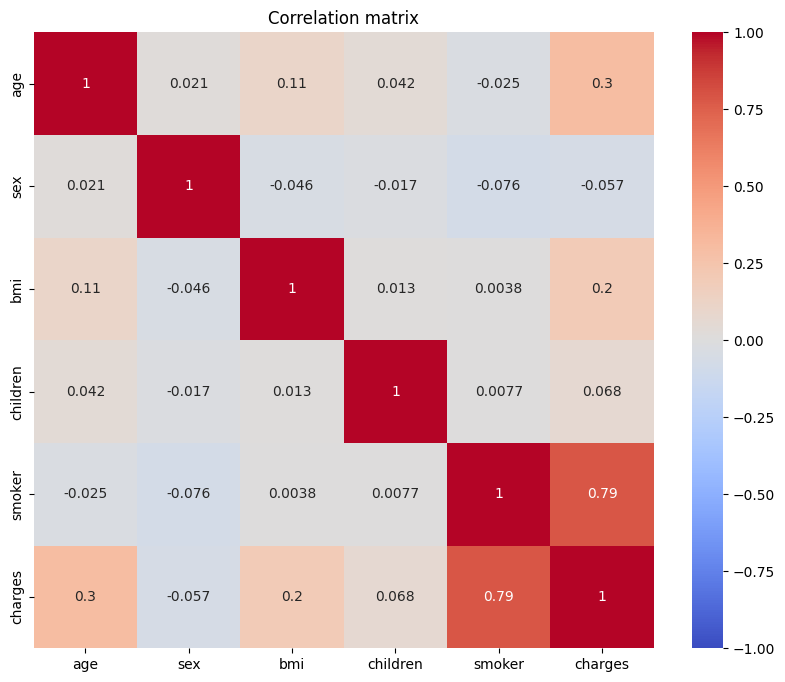

In [410]:
correlation_matrix=df1.corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",vmin=-1,vmax=1.00)
plt.title("Correlation matrix")
plt.show()

Multivariate analysis

interaction between age and smoking status and charges

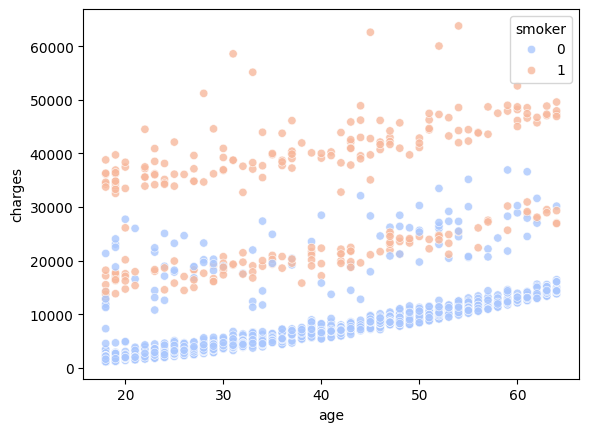

In [411]:
sns.scatterplot(x="age",y="charges",hue="smoker",data=df1,palette="coolwarm",alpha=0.8)
plt.xlabel("age")
plt.ylabel("charges")
plt.show()

interaction between age and sex status and charges

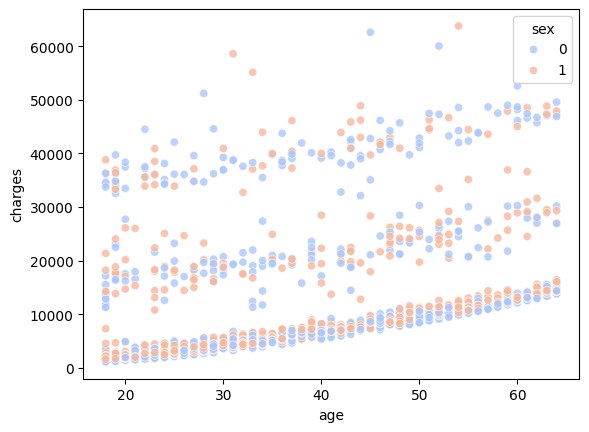

In [412]:
sns.scatterplot(x="age",y="charges",hue="sex",data=df1,palette="coolwarm",alpha=0.8)
plt.xlabel("age")
plt.ylabel("charges")
plt.show()

interaction between smoker, bmi and charges 

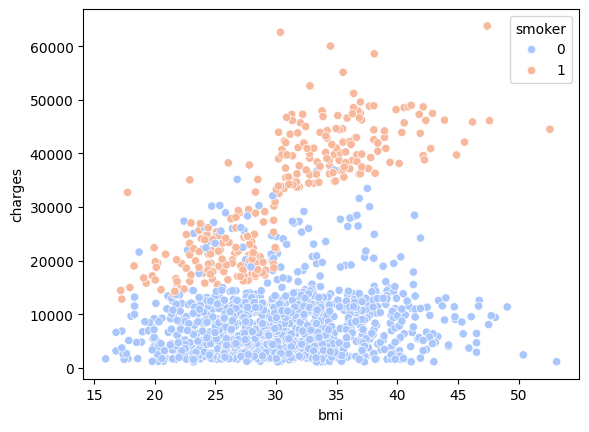

In [413]:
sns.scatterplot(x="bmi",y="charges",hue="smoker",palette="coolwarm",data=df1)
plt.xlabel("bmi")
plt.ylabel("charges")
plt.show()

interaction between smoker, bmi and charges 

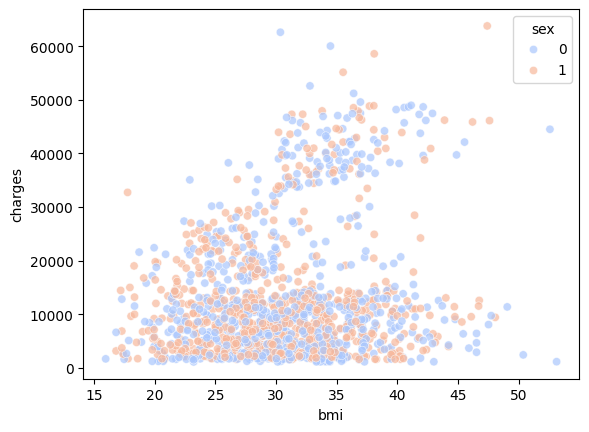

In [414]:
sns.scatterplot(x="bmi",y="charges",hue="sex",data=df1,palette="coolwarm",alpha=0.7)
plt.xlabel("bmi")
plt.ylabel("charges")
plt.show()

Graphical visualizations:
Use box plots

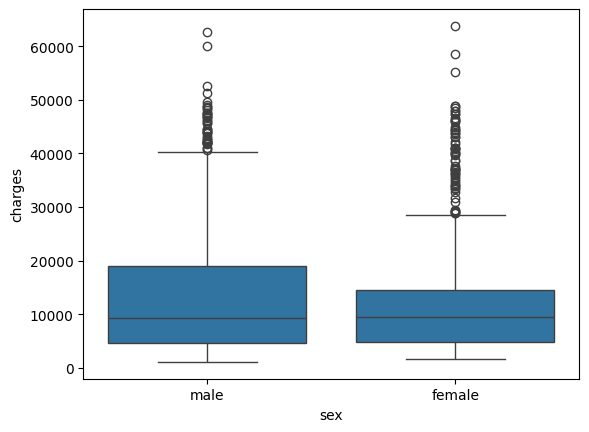

In [415]:
sns.boxplot(x="sex",y="charges",data=df1)
plt.xticks([0,1],["male","female"])
plt.show()

In [416]:
charges_male=df[df["sex"]==0]["charges"]
charges_female=df[df["sex"]==1]["charges"]
median_male=np.median(charges_male)
median_female=np.median(charges_female)
print("Median male",median_male )
print("Mediane_female",median_female)

Median male 9369.61575
Mediane_female 9412.9625


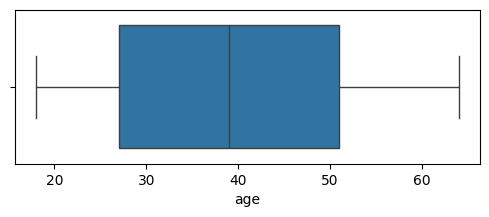

In [417]:
plt.figure(figsize=(6,2))
sns.boxplot(x="age",data=df1)
plt.show()

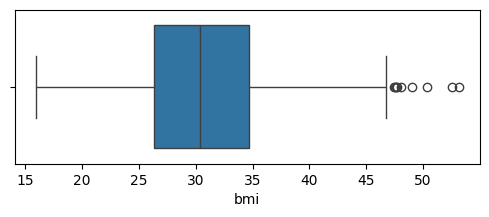

In [418]:
plt.figure(figsize=(6,2))
sns.boxplot(x="bmi",data=df1)
plt.show() 


C:\Users\OTHMANE\AppData\Local\Temp\ipykernel_1048\3922521112.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([charge_non_fumeurs,charge_fumeurs],labels=["No-smocker", "Smocker"])


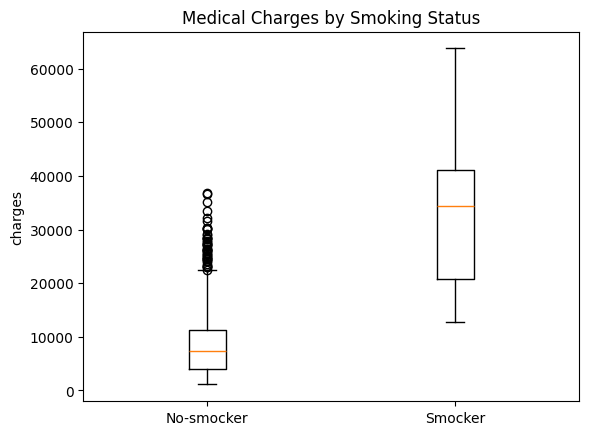

In [419]:
charge_non_fumeurs=df[df["smoker"]==0]["charges"]
charge_fumeurs=df[df["smoker"]==1]["charges"]
plt.boxplot([charge_non_fumeurs,charge_fumeurs],labels=["No-smocker", "Smocker"])
plt.title("Medical Charges by Smoking Status")
plt.ylabel("charges")
plt.show()

In [420]:
median_no_smocker=np.median(charge_non_fumeurs)
median_smocker=np.median(charge_fumeurs)
print("Mediane No_smocker",median_no_smocker)
print("Mediane Smoker",median_smocker)

Mediane No_smocker 7345.4053
Mediane Smoker 34456.348450000005
